# Classifying Crime Types in DC

**Team members:** Sufyan Billel, Ryan Fang, Eloise McDonough (Team 13)  
**Repository:** https://github.com/Brustachio/ds3001-semester-project/

---

### Question, Scope, and Data Provenance

* **Research Question:** Using DC's crime incident reports, do time of day, method, and location predict whether an incident is violent or property crime, and where do these results concentrate?
* **Data Source & Provenance:** DC Metropolitan Police Department (MPD) "Crime Incidents" reports (2024–2025) accessed via Open Data DC (`https://opendata.dc.gov/`). The dataset is public, documented, and directly accessible without licensing barriers.
* **Unit of Observation:** A single reported crime incident in Washington, DC.
* **Analytic Sample Criteria:**
  * **Included Data:** DC MPD Crime Incident reports from 2024–2025.
  * **Excluded Data:** Incidents missing offense classifications, geographic coordinates (LATITUDE, LONGITUDE, WARD), or valid start timestamps (START_DATE), as well as 311 service requests or non-MPD records.
* **Key Variables:**
  * **Target Outcome:** `OFFENSE` (9 raw MPD offense categories mapped into a binary classification target: `Violent = 1` vs. `Property = 0`).
  * **Geographic Predictors:** `WARD`, `LATITUDE`, `LONGITUDE`.
  * **Temporal Predictors:** `SHIFT`, `START_DATE` (parsed into separate date, `hour_clean`, `month_clean`, and `is_weekend_clean` variables).
  * **Tactical Predictor / Descriptive Variable:** `METHOD` (`GUN`, `KNIFE`, `OTHERS`).

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    precision_score,
    recall_score
)

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

## Load data

Following the course data wrangling rules, we never edit or overwrite the original source CSV files. We load the raw 2024 and 2025 datasets from `DATA_DIR`, combine them cleanly, and inspect `.shape`, `.dtypes`, and `.head()` to see how the variables are recorded.

In [2]:
# load data from DATA_DIR
file_2025 = DATA_DIR / "Crime_Incidents_in_2025.csv"
file_2024 = DATA_DIR / "Crime_Incidents_in_2024.csv"

df_2025 = pd.read_csv(file_2025, low_memory=False)
df_2025["source_year"] = 2025

if file_2024.exists():
    df_2024 = pd.read_csv(file_2024, low_memory=False)
    df_2024["source_year"] = 2024
    df = pd.concat([df_2024, df_2025], axis=0, ignore_index=True)
    print(f"Combined 2024 and 2025 datasets. Total shape: {df.shape}")
else:
    df = df_2025.copy()
    print(f"Loaded 2025 dataset (2024 CSV not yet in folder). Total shape: {df.shape}")

print("\nColumn Data Types:")
print(df.dtypes)

display(df.head())

Combined 2024 and 2025 datasets. Total shape: (53456, 26)

Column Data Types:
X                       float64
Y                       float64
CCN                       int64
REPORT_DAT                  str
START_DATE                  str
END_DATE                    str
BLOCK                       str
OFFENSE                     str
METHOD                      str
SHIFT                       str
WARD                    float64
ANC                         str
DISTRICT                float64
PSA                     float64
NEIGHBORHOOD_CLUSTER        str
BLOCK_GROUP                 str
CENSUS_TRACT            float64
VOTING_PRECINCT             str
BID                         str
XBLOCK                  float64
YBLOCK                  float64
LATITUDE                float64
LONGITUDE               float64
OBJECTID                  int64
OCTO_RECORD_ID          float64
source_year               int64
dtype: object


,X,Y,CCN,REPORT_DAT,START_DATE,END_DATE,BLOCK,OFFENSE,METHOD,SHIFT,...,CENSUS_TRACT,VOTING_PRECINCT,BID,XBLOCK,YBLOCK,LATITUDE,LONGITUDE,OBJECTID,OCTO_RECORD_ID,source_year
0,400040.6100,129046.4721,18060158,2024/07/30 04:00:00+00,2018/04/15 16:07:00+00,2018/04/15 17:34:56+00,400 - 599 BLOCK OF CHESAPEAKE STREET SE,HOMICIDE,GUN,MIDNIGHT,...,9802.0,Precinct 125,NaN,400040.610046,129046.472149,38.829204,-76.999532,1044228575,NaN,2024
1,402634.4900,139215.2500,24013178,2024/01/27 04:28:54+00,2024/01/27 03:59:00+00,2024/01/27 04:45:00+00,2300 - 2399 BLOCK OF BLADENSBURG ROAD NE,MOTOR VEHICLE THEFT,OTHERS,MIDNIGHT,...,11100.0,Precinct 71,NaN,402634.490000,139215.250000,38.920805,-76.969620,1044230866,NaN,2024
2,400686.4000,136474.3100,24014920,2024/01/30 14:45:41+00,2024/01/30 07:00:00+00,2024/01/30 08:00:00+00,1000 - 1099 BLOCK OF E STREET NE,THEFT F/AUTO,OTHERS,DAY,...,8100.0,Precinct 85,NaN,400686.400000,136474.310000,38.896117,-76.992087,1044231503,NaN,2024
3,400040.4376,129143.7717,24019381,2024/02/07 17:47:45+00,2024/02/07 13:25:00+00,2024/02/07 14:57:00+00,400 - 599 BLOCK OF BRANDYWINE STREET SE,MOTOR VEHICLE THEFT,OTHERS,DAY,...,9802.0,Precinct 125,NaN,400040.437598,129143.771733,38.830081,-76.999534,1044231504,NaN,2024
4,401747.9400,136474.1200,20201341,2024/12/30 20:40:12+00,2024/12/29 20:00:00+00,2024/12/29 20:30:00+00,1700 - 1799 BLOCK OF E STREET NE,THEFT/OTHER,OTHERS,EVENING,...,7901.0,Precinct 81,NaN,401747.940000,136474.120000,38.896114,-76.979851,1044259769,NaN,2024


## Prepare data

### 1. Fix Raw Variables and Track Missingness
Before building our models, we clean the raw variables according to course principles:
1. Keep all original columns intact (no silent overwrites).
2. For numeric predictors (`WARD`, `LATITUDE`, `LONGITUDE`), use `pd.to_numeric(..., errors='coerce')` to create `_clean` columns and explicitly record missing or coerced values in `_nan` indicator columns.
3. Inspect `.value_counts(dropna=False)` for `OFFENSE`, `SHIFT`, and `METHOD`, creating `_clean` and `_nan` columns for each.

In [3]:
# cleaning numeric geographic variables without silent overwrites
num_vars = ['WARD', 'LATITUDE', 'LONGITUDE']

for var in num_vars:
    df[f'{var}_clean'] = pd.to_numeric(df[var], errors='coerce')
    df[f'{var}_nan'] = df[f'{var}_clean'].isnull()

print('Missing or coerced values in numeric geographic variables:')
print(df[[f'{var}_nan' for var in num_vars]].sum(), '\n')

print('Summary statistics of cleaned numeric variables:')
display(df[[f'{var}_clean' for var in num_vars]].describe().round(4))

# checking categorical variables OFFENSE, SHIFT, and METHOD
cat_vars = ['OFFENSE', 'SHIFT', 'METHOD']

for var in cat_vars:
    df[f'{var}_clean'] = df[var].astype('string').str.strip()
    df[f'{var}_nan'] = df[f'{var}_clean'].isnull() | (df[f'{var}_clean'] == '')
    print(f'{var} Value Counts:')
    print(df[f'{var}_clean'].value_counts(dropna=False), '\n')

Missing or coerced values in numeric geographic variables:
WARD_nan         4
LATITUDE_nan     0
LONGITUDE_nan    0
dtype: int64 

Summary statistics of cleaned numeric variables:


,WARD_clean,LATITUDE_clean,LONGITUDE_clean
count,53452.0000,53456.0000,53456.0000
mean,4.3858,38.9087,-77.0090
std,2.3034,0.0307,0.0349
min,1.0000,38.8120,-77.1119
25%,2.0000,38.8951,-77.0320
50%,5.0000,38.9086,-77.0122
75%,6.0000,38.9266,-76.9872
max,8.0000,38.9942,-76.9100


OFFENSE Value Counts:
OFFENSE_clean
THEFT/OTHER                   24658
THEFT F/AUTO                  12044
MOTOR VEHICLE THEFT            9061
ROBBERY                        3435
ASSAULT W/DANGEROUS WEAPON     1960
BURGLARY                       1727
HOMICIDE                        314
SEX ABUSE                       249
ARSON                             8
Name: count, dtype: Int64 

SHIFT Value Counts:
SHIFT_clean
EVENING     21913
DAY         21461
MIDNIGHT    10082
Name: count, dtype: Int64 

METHOD Value Counts:
METHOD_clean
OTHERS    49162
GUN        3483
KNIFE       811
Name: count, dtype: Int64 



### 2. Target Construction, Temporal Parsing, and Analytic Sample Filtering
Following our project proposal, we map the 9 official MPD `OFFENSE` types into two distinct categories:
* **Violent Crime (`is_violent = 1`):** `HOMICIDE`, `SEX ABUSE`, `ASSAULT W/DANGEROUS WEAPON`, `ROBBERY`
* **Property Crime (`is_violent = 0`):** `BURGLARY`, `THEFT F/AUTO`, `THEFT/OTHER`, `MOTOR VEHICLE THEFT`, `ARSON`

**Temporal Features:** We parse `START_DATE` to extract `hour_clean` (`0`–`23`), `month_clean`, `dayofweek_clean`, and a binary `is_weekend_clean` indicator.
* **Filtering & Saving:** We filter out observations missing offense classifications, coordinates, ward, or valid start timestamps, and save the cleaned dataset to `data/Crime_Incidents_Clean+Combined.csv`.

In [4]:
violent_offenses = [
    'HOMICIDE',
    'SEX ABUSE',
    'ASSAULT W/DANGEROUS WEAPON',
    'ROBBERY'
]

property_offenses = [
    'BURGLARY',
    'THEFT F/AUTO',
    'THEFT/OTHER',
    'MOTOR VEHICLE THEFT',
    'ARSON'
]

# construct categorical label and binary indicator in new columns
df['crime_category_clean'] = np.where(
    df['OFFENSE_clean'].isin(violent_offenses), 'Violent',
    np.where(df['OFFENSE_clean'].isin(property_offenses), 'Property', pd.NA)
)
df['crime_category_nan'] = df['crime_category_clean'].isnull()

df['is_violent_clean'] = np.where(
    df['crime_category_clean'] == 'Violent', 1.0,
    np.where(df['crime_category_clean'] == 'Property', 0.0, np.nan)
)

# parse START_DATE into datetime format safely
df['START_DATE_dt'] = pd.to_datetime(df['START_DATE'], errors='coerce')
df['START_DATE_nan'] = df['START_DATE_dt'].isnull()

# extract separate date and time components
df['incident_date_clean'] = df['START_DATE_dt'].dt.date
df['hour_clean'] = df['START_DATE_dt'].dt.hour
df['month_clean'] = df['START_DATE_dt'].dt.month
df['dayofweek_clean'] = df['START_DATE_dt'].dt.day_name()
df['is_weekend_clean'] = df['START_DATE_dt'].dt.day_of_week.isin([5, 6]).astype(int)
# filter rows based on explicit exclusion criteria
valid_condition = (
    (~df["crime_category_nan"]) &
    (~df["LATITUDE_nan"]) &
    (~df["LONGITUDE_nan"]) &
    (~df["WARD_nan"]) &
    (~df["START_DATE_nan"]) &
    (~df["SHIFT_nan"]) &
    (~df["METHOD_nan"])
)

df_clean = df.loc[valid_condition].copy()
df_clean["WARD_str"] = df_clean["WARD_clean"].astype(int).astype(str)

print(f"Missing/unparseable START_DATE values: {df['START_DATE_nan'].sum()}" + "\n")

print(f"Original row count (N): {len(df)}")
print(f"Cleaned analytic sample row count (N): {len(df_clean)}")
print(f"Rows excluded due to missingness: {len(df) - len(df_clean)}\n")

print("Crime Category Distribution (Counts & Proportions):")
print(df_clean["crime_category_clean"].value_counts())
print("\n")
print(df_clean["crime_category_clean"].value_counts(normalize=True).round(4))

# save a separate cleaned copy into DATA_DIR without overwriting raw CSVs
df_clean.to_csv(DATA_DIR / "Crime_Incidents_Clean+Combined.csv", index=False)

Missing/unparseable START_DATE values: 5

Original row count (N): 53456
Cleaned analytic sample row count (N): 53447
Rows excluded due to missingness: 9

Crime Category Distribution (Counts & Proportions):
crime_category_clean
Property    47491
Violent      5956
Name: count, dtype: int64


crime_category_clean
Property    0.8886
Violent     0.1114
Name: proportion, dtype: float64


## Explore data

### 1. Distributions by Offense Type, Time of Day, Shift, and Ward
We begin our Exploratory Data Analysis (EDA) by examining the distribution of the 9 offense types and conditioning on `crime_category_clean` (`Violent` vs. `Property`) across hours of the day, police shifts, and DC Wards. This should hopefully assist us in making models easier

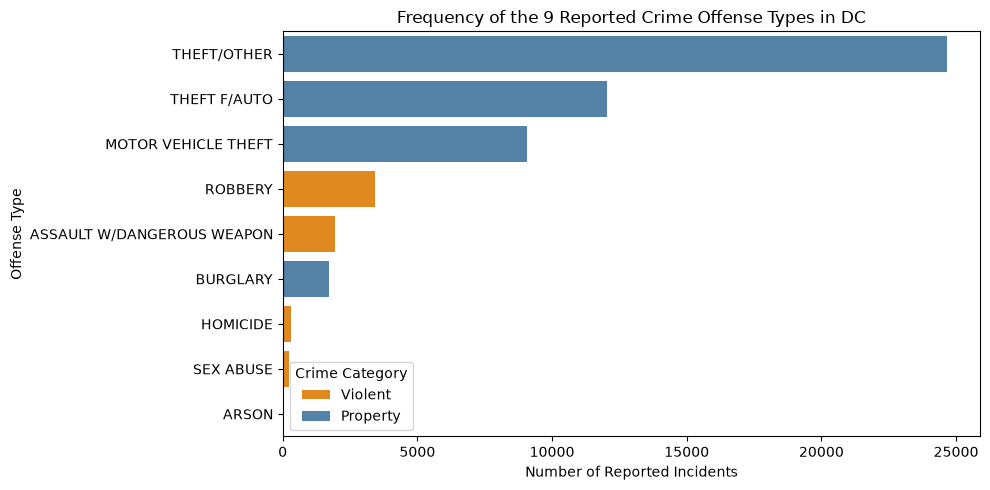

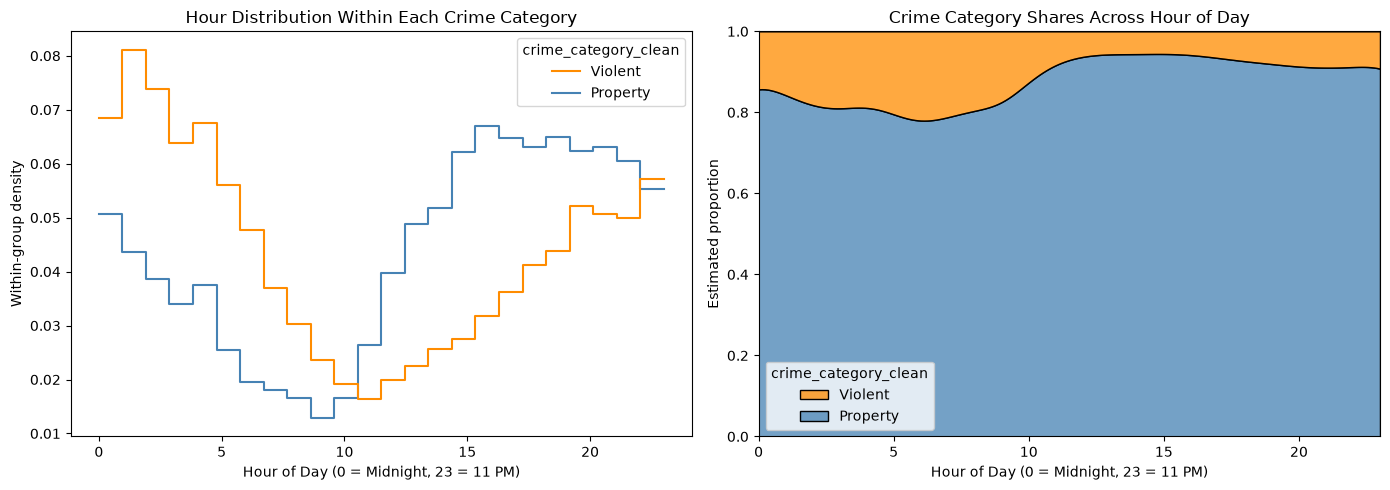

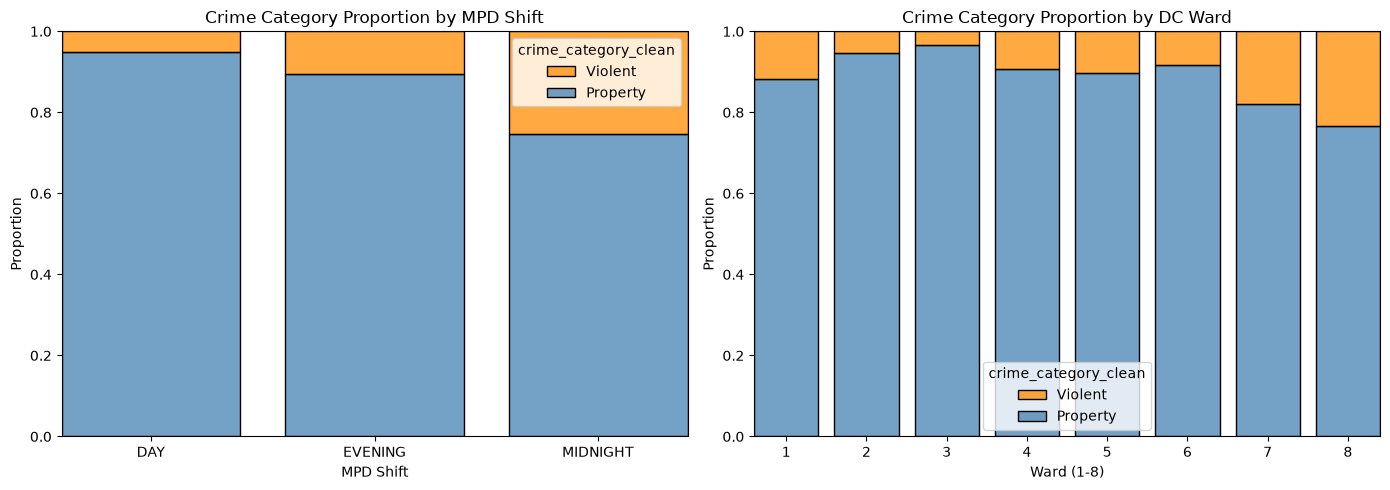

In [5]:
# summarize and visualize the prepared data
# single-variable distribution: Counts of the 9 specific OFFENSE types
plt.figure(figsize=(10, 5))
offense_order = df_clean["OFFENSE_clean"].value_counts().index
sns.countplot(
    data=df_clean,
    y="OFFENSE_clean",
    hue="crime_category_clean",
    order=offense_order,
    palette={"Property": "steelblue", "Violent": "darkorange"}
)
plt.title("Frequency of the 9 Reported Crime Offense Types in DC")
plt.xlabel("Number of Reported Incidents")
plt.ylabel("Offense Type")
plt.legend(title="Crime Category")
plt.tight_layout()
plt.show()

# numeric x categorical: Within-group density and stacked density across Hour of Day
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_clean,
    x="hour_clean",
    hue="crime_category_clean",
    stat="density",
    common_norm=False,
    multiple="layer",
    element="step",
    fill=False,
    bins=24,
    palette={"Property": "steelblue", "Violent": "darkorange"},
    ax=axes[0]
)
axes[0].set(
    title="Hour Distribution Within Each Crime Category",
    xlabel="Hour of Day (0 = Midnight, 23 = 11 PM)",
    ylabel="Within-group density"
)

sns.kdeplot(
    data=df_clean,
    x="hour_clean",
    hue="crime_category_clean",
    multiple="fill",
    cut=0,
    palette={"Property": "steelblue", "Violent": "darkorange"},
    ax=axes[1]
)
axes[1].set(
    title="Crime Category Shares Across Hour of Day",
    xlabel="Hour of Day (0 = Midnight, 23 = 11 PM)",
    ylabel="Estimated proportion"
)

plt.tight_layout()
plt.show()

# categorical x categorical: Stacked bar plots for SHIFT and WARD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_clean["SHIFT_ordered"] = pd.Categorical(
    df_clean["SHIFT_clean"], categories=["DAY", "EVENING", "MIDNIGHT"], ordered=True
)
df_clean["WARD_ordered"] = pd.Categorical(
    df_clean["WARD_str"], categories=[str(i) for i in range(1, 9)], ordered=True
)

sns.histplot(
    data=df_clean,
    x="SHIFT_ordered",
    hue="crime_category_clean",
    multiple="fill",
    discrete=True,
    shrink=0.8,
    palette={"Property": "steelblue", "Violent": "darkorange"},
    ax=axes[0]
)
axes[0].set(
    title="Crime Category Proportion by MPD Shift",
    xlabel="MPD Shift",
    ylabel="Proportion"
)

sns.histplot(
    data=df_clean,
    x="WARD_ordered",
    hue="crime_category_clean",
    multiple="fill",
    discrete=True,
    shrink=0.8,
    palette={"Property": "steelblue", "Violent": "darkorange"},
    ax=axes[1]
)
axes[1].set(
    title="Crime Category Proportion by DC Ward",
    xlabel="Ward (1-8)",
    ylabel="Proportion"
)

plt.tight_layout()
plt.show()

### 2. Correlation Analysis & Identifying Nonlinear Relationships
To determine which modeling families and feature specifications are most appropriate, we will try to find where the strongest linear and nonlinear correlations are:
1. **Feature-Target Linear Correlations ($r$):** We compute correlations between `is_violent_clean` and all spatial, temporal, and tactical indicators.
2. **Limits of Linear Association Over Restricted Ranges (`hour_clean`):** Similar to what's in the A02 EDA lecture slides, a single correlation over the full range of a variable can be near zero when the two sides of a curve have opposite slopes. Because violent crime share drops from early morning to midday and rises from afternoon through midnight, we check the correlation over restricted hour ranges (`Hours 5–14` vs. `Hours 14–23`).
3. **Fallback Investigation (`METHOD` Cross-Tabulation):** We cross-tabulate `METHOD_clean` against `crime_category_clean` to quantify how strongly weapon indicators separate violent from property crime.

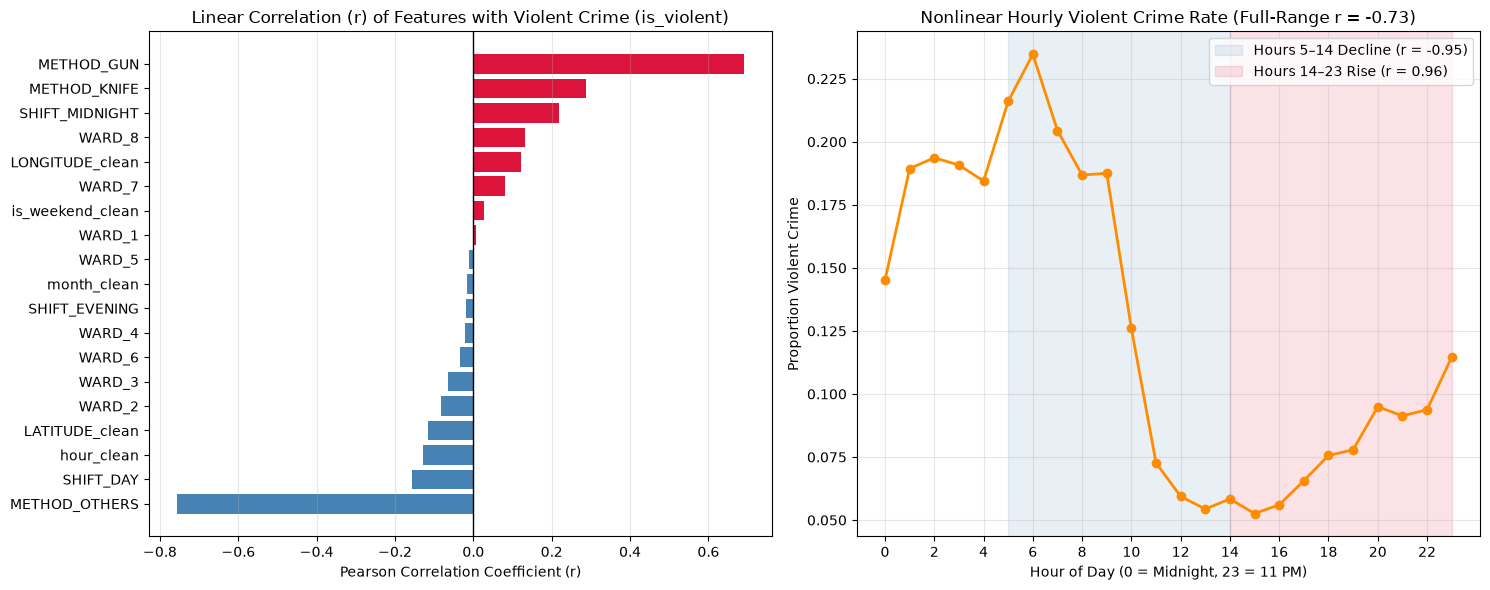

Cross-Tabulation of METHOD by Crime Category (Row Proportions):


METHOD_clean,GUN,KNIFE,OTHERS
crime_category_clean,,,
Property,0.0048,0.0027,0.9925
Violent,0.5462,0.1145,0.3393


In [6]:
# create indicator variables for full correlation inspection
shift_dummies_all = pd.get_dummies(df_clean["SHIFT_clean"], prefix="SHIFT", dtype=int)
ward_dummies_all = pd.get_dummies(df_clean["WARD_clean"].astype(int), prefix="WARD", dtype=int)
method_dummies_all = pd.get_dummies(df_clean["METHOD_clean"], prefix="METHOD", dtype=int)

corr_df = pd.concat([
    df_clean[["is_violent_clean", "LATITUDE_clean", "LONGITUDE_clean", "hour_clean", "month_clean", "is_weekend_clean"]],
    shift_dummies_all,
    ward_dummies_all,
    method_dummies_all
], axis=1)

# compute correlations with the binary target is_violent_clean
target_corrs = corr_df.corr()["is_violent_clean"].drop("is_violent_clean").sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: Horizontal bar chart of correlations with is_violent_clean
bar_colors = ["crimson" if val > 0 else "steelblue" for val in target_corrs.values]
axes[0].barh(target_corrs.index, target_corrs.values, color=bar_colors)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("Linear Correlation (r) of Features with Violent Crime (is_violent)")
axes[0].set_xlabel("Pearson Correlation Coefficient (r)")
axes[0].grid(axis="x", alpha=0.3)

# Right: Nonlinear U-shaped relationship of Violent Crime Share across Hour of Day
hourly_violent_share = df_clean.groupby("hour_clean")["is_violent_clean"].mean()
r_all = hourly_violent_share.index.to_series().corr(hourly_violent_share)
r_day_drop = hourly_violent_share.loc[5:14].index.to_series().corr(hourly_violent_share.loc[5:14])
r_night_rise = hourly_violent_share.loc[14:23].index.to_series().corr(hourly_violent_share.loc[14:23])

axes[1].plot(hourly_violent_share.index, hourly_violent_share.values, marker="o", color="darkorange", linewidth=2)
axes[1].axvspan(5, 14, color="steelblue", alpha=0.12, label=f"Hours 5–14 Decline (r = {r_day_drop:.2f})")
axes[1].axvspan(14, 23, color="crimson", alpha=0.12, label=f"Hours 14–23 Rise (r = {r_night_rise:.2f})")
axes[1].set_title(f"Nonlinear Hourly Violent Crime Rate (Full-Range r = {r_all:.2f})")
axes[1].set_xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
axes[1].set_ylabel("Proportion Violent Crime")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Cross-Tabulation of METHOD by Crime Category (Row Proportions):")
display(pd.crosstab(df_clean["crime_category_clean"], df_clean["METHOD_clean"], normalize="index").round(4))

**How Our Correlation Findings Guide Model & Specification Choices:**
1. **Tactical Predictors (`METHOD_GUN` $r = +0.69$, `METHOD_KNIFE` $r = +0.29$, `METHOD_OTHERS` $r = -0.76$):** `METHOD` has the strongest linear correlation with violent crime because 99.25% of property crimes are recorded as `'OTHERS'`, whereas `'GUN'` and `'KNIFE'` occur almost exclusively in violent offenses. To rigorously test both our main question and our fallback plan, we benchmark every model under **two explicit specifications**:
   * **Specification A (Spatial-Temporal Fallback):** Uses only location (`LATITUDE_clean`, `LONGITUDE_clean`, `WARD`) and time (`hour_clean`, `is_weekend_clean`, `SHIFT`), omitting `METHOD`.
   * **Specification B (Full Specification):** Includes location, time, and `METHOD` indicators (`METHOD_GUN`, `METHOD_KNIFE`).
2. **Temporal Predictors (`SHIFT_MIDNIGHT` $r = +0.22$, `SHIFT_DAY` $r = -0.16$, Nonlinear `hour_clean`):** Across all 24 hours, incident-level `hour_clean` has a weak overall linear correlation ($r = -0.13$, and $r = -0.73$ across hourly violent crime rates) because violent crime peaks late at night (`Hours 0–4` and `21–23`), drops sharply from 5 AM to 2 PM ($r = -0.95$), and climbs sharply from 2 PM to 11 PM ($r = +0.96$). Including `SHIFT` dummy variables helps a **Linear Regression** model capture these regime shifts, while **$k$-Nearest Neighbors ($k$-NN)** can naturally adapt to local nonlinear time and coordinate boundaries.
3. **Geographic Predictors (`WARD_8` $r = +0.13$, `WARD_7` $r = +0.08$, `LATITUDE_clean` $r = -0.12$, `LONGITUDE_clean` $r = +0.12$):** Violent crime correlates positively with southeastern coordinates (lower latitude, higher longitude, Wards 7 and 8) and negatively with northwestern wards (Wards 2 and 3).

## Build models

In [7]:
# Train baseline and candidate models.

## Evaluate models

In [8]:
# Compare models using the chosen evaluation measures.

## Final results

In [9]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]